# Better

In [1]:
#Modules
import sys, os
sys.path.insert(0, './Models')
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import RegularGridInterpolator
import pandas as pd
%matplotlib inline

In [2]:
#constants and astronomical units
M_e   = 5.972e24  #Earth mass (kg)
R_e   = 6.371e6   #Earth radius (m)

M_sun = 1.988e30  #Solar mass (kg)
R_sun = 6.955e10  #Solar radius (m)
L_sun = 3.828e26  #luminosity of the Sun (Watts, kg⋅m^2⋅s^-3)
T_sun = 5778      #Solar temperature (K)

au    = 1.496e11  #astronomical unit (m)
Gyr   = 3.153e16  #seconds in 1 billion years
G     = 6.674e-11 #gravitational constant (m^3⋅kg^-1⋅s^-2)

savepath = 'paper/plots'
path_models='./Models/'

### Composition Curves *(Aguichine+2025, Zeng+2016)*

In [3]:
xmin, xmax, nx = 0.1, 20-1e-5, 50 # 0.5, 20
ymin, ymax  = .75, 4.25
x = np.logspace(np.log10(xmin), np.log10(xmax), nx)

#MARDIGRAS stuff
xmin, xmax, nx = 0.1, 19.99999, 50 # 0.5, 20
ymin, ymax  = .75, 4.25

##############################################
#   MAKE SWEET INTERPOLATOR (Aguichine+2025)
path_sweet = path_models + "Aguichine2025_SWEET_all.dat"
sweet_top = np.array([0,1])
sweet_labels_top = ["20 mbar", "1 µbar"]
sweet_labels_host = ["Type M", "Type G"]
sweet_teqs = np.array([400, 500, 700, 900, 1100, 1300, 1500])
sweet_wmfs = np.array([0.1,1,10,20,30,40,50,60,70,80,90,100])
sweet_masses = np.array([0.2       ,  0.254855  ,  0.32475535,  0.41382762,  0.52733018,
        0.67196366,  0.85626648,  1.09111896,  1.39038559,  1.77173358,
        2.25767578,  2.87689978,  3.66596142,  4.67144294,  5.95270288,
        7.58538038,  9.66586048, 12.31696422, 15.69519941, 20.        ])
sweet_ages = np.array([0.001,0.0015,0.002,0.003,0.005,0.01,
                        0.02,0.03,0.05,
                        0.1,0.2,0.5,
                        1.0,2.0,5.0,
                        10,20])
sweet_dim_wmf = sweet_wmfs.copy()/100
sweet_dim_teq = sweet_teqs.copy()
sweet_dim_mass = sweet_masses.copy()
sweet_dim_age = sweet_ages.copy()
sweet_dim_star = np.array([0,1])
sweet_dim_top = np.array([0,1])

listrpfull1 = np.loadtxt(path_sweet,skiprows=36,unpack=True,usecols=(6))
listrpfull2 = np.loadtxt(path_sweet,skiprows=36,unpack=True,usecols=(7))
listrpfull = np.array((listrpfull1,listrpfull2))
listrpfull = np.delete(listrpfull, np.arange(17, listrpfull.size, 18))

sweet_data_radius = np.reshape(listrpfull,(2,2,12,7,20,17))
mask = np.isnan(sweet_data_radius)
sweet_data_radius[mask] = -1

fill_value = None       # fill_value: value to return when extrapolating beyond grid validity range
interp_sweet = RegularGridInterpolator((sweet_dim_top,
                                      sweet_dim_star,
                                      sweet_dim_wmf,
                                      sweet_dim_teq,
                                      sweet_dim_mass,
                                      sweet_dim_age), 
                                     sweet_data_radius, method='slinear', bounds_error=False, fill_value=fill_value)


# The parametrized function to be plotted
def radius_m(x,wmf_swe,teq_swe,age_swe):
    input0 = np.stack([np.full(len(x),0), np.full(len(x),0), np.full(len(x),wmf_swe), np.full(len(x),teq_swe), x, np.full(len(x),age_swe)],axis=-1)
    return interp_sweet(input0)

def radius_g(x,wmf_swe,teq_swe,age_swe):
    input0 = np.stack([np.full(len(x),0), np.full(len(x),1), np.full(len(x),wmf_swe), np.full(len(x),teq_swe), x, np.full(len(x),age_swe)],axis=-1)
    return interp_sweet(input0)

# Define initial parameters
init_host_swe = 0
init_wmf_swe = 0.5
init_teq_swe = 600.0
init_age_swe = 1.0
init_wmf_swe100 = 1.0
swe_func = [radius_m, radius_g]
swe_labels = ["Type M", "Type G"]  # Optional labels for each 

##############################################
#   MAKE ZENG INTERPOLATOR (Zeng+2016)
init_cmf_zeng = 0.325
list_zeng_fe_m,list_zeng_fe_r = np.loadtxt(path_models+"zeng2016-iron.dat",unpack=True,usecols=(0,1))
list_zeng_ea_m,list_zeng_ea_r = np.loadtxt(path_models+"zeng2016-earth.dat",unpack=True,usecols=(0,1))
list_zeng_mg_m,list_zeng_mg_r = np.loadtxt(path_models+"zeng2016-rock.dat",unpack=True,usecols=(0,1))
list_zeng_masses = np.logspace(np.log10(0.01), np.log10(100.0), 30)

# reshape radius data to the same vector
list_zeng_fe_radii = np.interp(list_zeng_masses, list_zeng_fe_m, list_zeng_fe_r)
list_zeng_ea_radii = np.interp(list_zeng_masses, list_zeng_ea_m, list_zeng_ea_r)
list_zeng_mg_radii = np.interp(list_zeng_masses, list_zeng_mg_m, list_zeng_mg_r)

# create interpolator
dimcmf_zeng = np.array([0.0,0.325,1.0])
data_zeng = np.vstack((list_zeng_mg_radii, list_zeng_ea_radii,list_zeng_fe_radii)).T
interp_zeng = RegularGridInterpolator((list_zeng_masses,dimcmf_zeng), data_zeng, method='linear', bounds_error=False, fill_value=None)

# parameterized func to plot
def rad_zeng(x,cmf):
    input0 = np.stack((x,np.full(len(x),cmf)), axis=-1)
    rp = interp_zeng(input0)
    return rp

### PlanetS Catalog

In [4]:
catalog='PlanetS'
# File paths and URL of the PlanetS Catalog
planets_catalog_url = ("None")
planets_output_file = "./Models/catalog_exoplanets_planets.dat"

# Load PlanetS data
data_planets = np.genfromtxt(planets_output_file, delimiter="\t", unpack=True,
                             usecols=(1,2,3,4,5,6,7,8,9),filling_values=0.0)

list_catalog_rp = data_planets[0]
list_catalog_rpe1 = data_planets[1]
list_catalog_rpe2 = data_planets[2]
list_catalog_mp = data_planets[3]
list_catalog_mpe1 = data_planets[4]
list_catalog_mpe2 = data_planets[5]
list_catalog_T = data_planets[6] #"pl_peri"
list_catalog_Te1 = data_planets[7]
list_catalog_Te2 = data_planets[8]

# Load the exoplanet names
list_catalog_names = np.genfromtxt( 
    planets_output_file, delimiter="\t", dtype=str, usecols=0 )

# Remove lines with empty Mp and Rp
exo_mass_prec = 0.5
filter_planets = (list_catalog_rp!=0) & (list_catalog_mp!=0.0)

list_exo_rp = list_catalog_rp[filter_planets]
list_exo_rpe1 = list_catalog_rpe1[filter_planets]
list_exo_rpe2 = list_catalog_rpe2[filter_planets]
list_exo_mp = list_catalog_mp[filter_planets]
list_exo_mpe1 = list_catalog_mpe1[filter_planets]
list_exo_mpe2 = list_catalog_mpe2[filter_planets]
list_exo_T = list_catalog_T[filter_planets]
list_exo_Te1 = list_catalog_Te1[filter_planets]
list_exo_Te2 = list_catalog_Te2[filter_planets]
list_exo_names = list_catalog_names[filter_planets]

### NEA Catalog

In [5]:
NEA_TABLE = "ps"
base_dir = os.getcwd()
catalogue_data_dir = os.path.join(base_dir, "cat")
def _select_local_nea_file(table_name: str) -> str:
    """Return the newest local NEA CSV matching the requested table."""
    cat_dir = os.path.join(catalogue_data_dir, "NEA")
    if not os.path.isdir(cat_dir):
        raise FileNotFoundError(f"Directory not found: {cat_dir}")

    prefixes = {
        "ps": "PS_",
        "pscomppars": "PSCompPars_",
    }
    if table_name not in prefixes:
        raise ValueError("NEA_TABLE must be 'ps' or 'pscomppars'.")

    prefix = prefixes[table_name].lower()
    files = sorted(
        f for f in os.listdir(cat_dir)
        if f.lower().endswith(".csv") and f.lower().startswith(prefix)
    )
    if not files:
        raise FileNotFoundError(
            f"No local {table_name} CSV files found in {cat_dir}."
        )

    return os.path.join(cat_dir, files[-1])


def _load_local_nea_catalogue(table_name: str) -> pd.DataFrame:
    """Load a local NEA catalogue and keep one adopted solution per planet."""
    path = _select_local_nea_file(table_name)
    df = pd.read_csv(path, comment="#")

    if table_name == "ps":
        if "default_flag" not in df.columns:
            raise KeyError(
                "The selected ps file does not contain 'default_flag'."
            )
        df = df.loc[df["default_flag"] == 1].copy()

    if "pl_name" in df.columns:
        df = df.drop_duplicates(subset="pl_name", keep="first").copy()

    return df.reset_index(drop=True)


def load_catalog_PR(catalog, precision_radius=30.0, precision_mass=0.0):
    """
    Load a period–radius catalogue and apply basic quality cuts.
    """
    if catalog == "NEA":
        df = _load_local_nea_catalogue(NEA_TABLE)

    elif catalog == "Exoplanet.eu":
        cat_dir = os.path.join(catalogue_data_dir, "Exoplanet.eu")
        if not os.path.isdir(cat_dir):
            raise FileNotFoundError(f"Directory not found: {cat_dir}")

        files = sorted(f for f in os.listdir(cat_dir) if f.lower().endswith(".csv"))
        if not files:
            raise FileNotFoundError(f"No CSV files found in {cat_dir}.")
        df = pd.read_csv(os.path.join(cat_dir, files[-1]))

        rename_map = {
            "orbital_period": "pl_orbper",
            "radius": "pl_rade",
            "radius_error_min": "pl_radeerr2",
            "radius_error_max": "pl_radeerr1",
        }
        if "mass" in df.columns:
            rename_map["mass"] = "pl_bmasse"
        if "mass_error_min" in df.columns:
            rename_map["mass_error_min"] = "pl_bmasseerr2"
        if "mass_error_max" in df.columns:
            rename_map["mass_error_max"] = "pl_bmasseerr1"

        df = df.rename(columns=rename_map)

        if "pl_bmasse" in df.columns:
            mjup_to_mearth = 317.828
            df["pl_bmasse"] *= mjup_to_mearth
            if "pl_bmasseerr1" in df.columns:
                df["pl_bmasseerr1"] *= mjup_to_mearth
            if "pl_bmasseerr2" in df.columns:
                df["pl_bmasseerr2"] *= mjup_to_mearth

        if "pl_rade" in df.columns:
            rjup_to_rearth = 11.209
            df["pl_rade"] *= rjup_to_rearth
            if "pl_radeerr1" in df.columns:
                df["pl_radeerr1"] *= rjup_to_rearth
            if "pl_radeerr2" in df.columns:
                df["pl_radeerr2"] *= rjup_to_rearth

    else:
        raise ValueError("catalog must be 'NEA' or 'Exoplanet.eu'.")

    required_cols = {"pl_orbper", "pl_rade"}
    missing_cols = required_cols - set(df.columns)
    if missing_cols:
        raise KeyError(f"Missing required catalogue columns: {sorted(missing_cols)}")

    mask_phys = (
        np.isfinite(df["pl_orbper"].values)
        & np.isfinite(df["pl_rade"].values)
        & (df["pl_orbper"].values > 0.0)
        & (df["pl_rade"].values > 0.0)
    )
    df = df.loc[mask_phys].copy()

    if precision_mass > 0.0 and {"pl_bmasse", "pl_bmasseerr1", "pl_bmasseerr2"}.issubset(df.columns):
        M_pl = df["pl_bmasse"].values
        M_err = 0.5 * (
            np.abs(df["pl_bmasseerr1"].values)
            + np.abs(df["pl_bmasseerr2"].values)
        )
        mask_M = (
            np.isfinite(M_pl)
            & np.isfinite(M_err)
            & (M_pl > 0.0)
            & ((M_err / M_pl) < (precision_mass / 100.0))
        )
        df = df.loc[mask_M].copy()

    if precision_radius > 0.0 and {"pl_rade", "pl_radeerr1", "pl_radeerr2"}.issubset(df.columns):
        R_pl = df["pl_rade"].values
        R_err = 0.5 * (
            np.abs(df["pl_radeerr1"].values)
            + np.abs(df["pl_radeerr2"].values)
        )
        mask_R = (
            np.isfinite(R_pl)
            & np.isfinite(R_err)
            & (R_pl > 0.0)
            & ((R_err / R_pl) < (precision_radius / 100.0))
        )
        df = df.loc[mask_R].copy()

    P_catalog = df["pl_orbper"].to_numpy(float)
    R_catalog = df["pl_rade"].to_numpy(float)
    return df.reset_index(drop=True), P_catalog, R_catalog

NEA_df, P_NEA, R_NEA = load_catalog_PR("NEA")

# Stacked M-R KDE's

In [6]:
#load in data
n_planets = 5000
fname = f'paper/{n_planets}_xp/{n_planets}_xp_gp_data.csv'
init_data_df = pd.read_csv(fname, sep='\t')
init_data_df['Rstar (m)'] = (init_data_df['Mstar (kg)']/1.988e30 * 6.955e10) **0.57
init_data_df['Rochelim (m)'] = 2**0.333 * (init_data_df['Rp (m)']) * (init_data_df['Mstar (kg)']/init_data_df['Mp (kg)'])**0.333
print(init_data_df.keys())

#Unicorns killed
iris = init_data_df[ (init_data_df['Rochelim (m)'] < init_data_df['sep (m)'])] #Planets outside the roche limit
# df3 = df2[df2['sep (m)'] / df2['Rochelim (m)'] > 1]

Index(['# Planet/5000', 'Mp (kg)', 'Rp (m)', 'Core M (kg)',
       'Surface Radius (m)', 'Teq (K)', 'WMF', 'gravity(m/s^2)',
       'scale height (m)', 'lambda', 'sep (m)', 'period (days)', 'G-Star Type',
       'Mstar (kg)', 'Lstar (W)', 'Fxuv (W/m^2)', 'Rstar (m)', 'Rochelim (m)'],
      dtype='object')


### Stuff for Sagnick

In [10]:
mtype = init_data_df['G-Star Type'] < 1

(array([ 18.,  49., 117., 238., 427., 576., 603., 561., 384., 179.]),
 array([1.162717  , 1.36497457, 1.56723215, 1.76948972, 1.97174729,
        2.17400487, 2.37626244, 2.57852001, 2.78077759, 2.98303516,
        3.18529273]),
 <BarContainer object of 10 artists>)

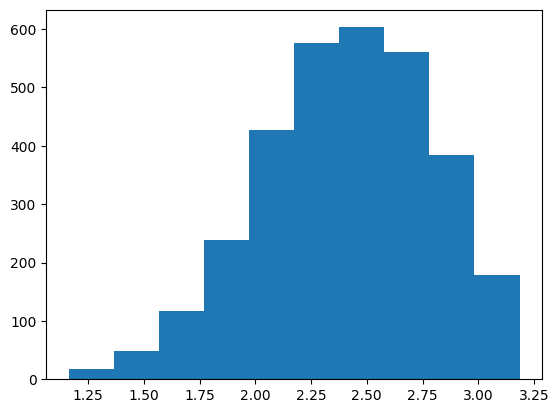

In [11]:
plt.hist(init_data_df[~mtype]['Rp (m)']/R_e)

In [15]:
all_end = np.array([])
datafolder='paper/5000_xp'

for i in range(5000):
    planetnum=i+1
    # import a planet's evolutionary track (just mp_gp and rp_gp)
    filename = f'{datafolder}/H2O/planet_{planetnum}-{n_planets}_evolution_data.csv'
    rp_gp = np.loadtxt(filename,usecols=(2),unpack=True)
    all_end = np.append(all_end, rp_gp[-2])

(array([ 16.,  40.,  83., 184., 227., 309., 330., 349., 226.,  84.]),
 array([1.18909276, 1.36229305, 1.53549333, 1.70869361, 1.88189389,
        2.05509418, 2.22829446, 2.40149474, 2.57469502, 2.74789531,
        2.92109559]),
 <BarContainer object of 10 artists>)

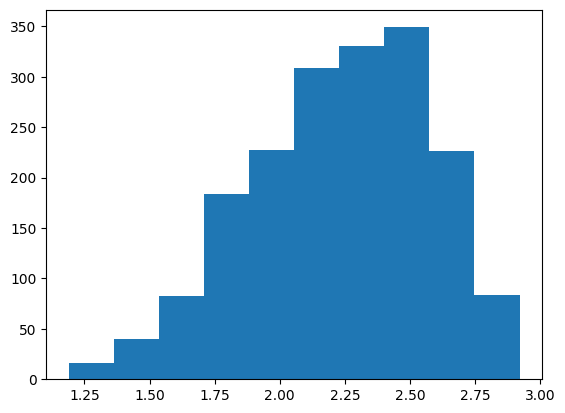

In [16]:
plt.hist(all_end[mtype]/R_e)

(array([ 21.,  65., 128., 283., 432., 572., 611., 537., 389., 114.]),
 array([1.2024329 , 1.3839052 , 1.56537749, 1.74684979, 1.92832208,
        2.10979438, 2.29126668, 2.47273897, 2.65421127, 2.83568357,
        3.01715586]),
 <BarContainer object of 10 artists>)

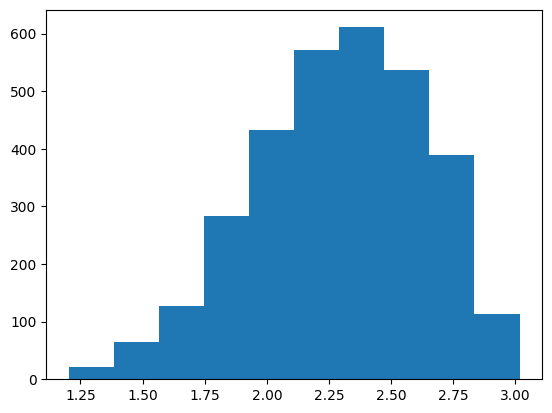

In [17]:
plt.hist(all_end[~mtype]/R_e)

## Two-Panel KDE MR

4469


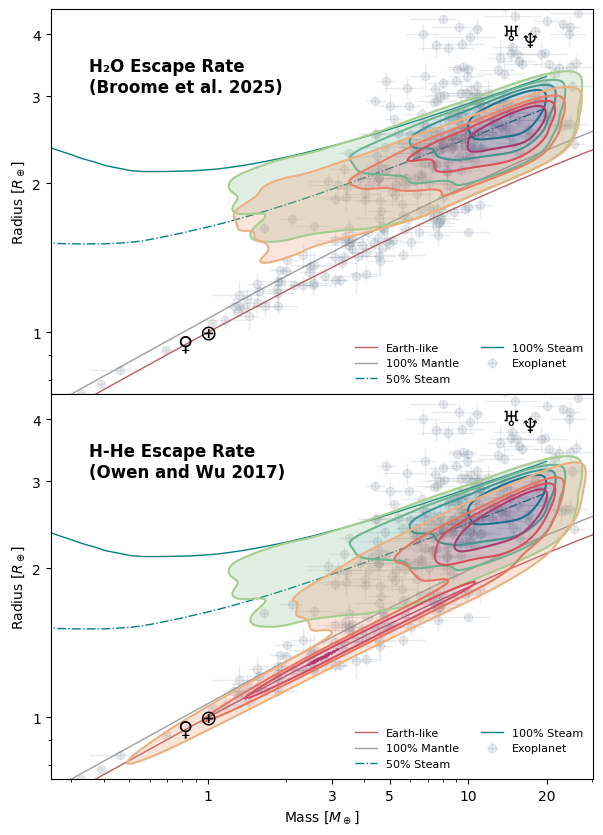

In [24]:
#two panels
fig, ax = plt.subplots(2,1, figsize=(7,10))#, sharex=True)
fig.subplots_adjust(hspace=0) 

mdot_text = 'M' + '\u0307'
datafolder = './paper/5000_xp'
types = ['H2O', 'H-He']
typelabel = [f'H\u2082O Escape Rate \n(Broome et al. 2025)', 'H-He Escape Rate \n(Owen and Wu 2017)']

colors = [sns.cm.crest, sns.cm.flare]
levels = 5
fill_a = 0.25

print(len(iris['# Planet/5000']))

#Plot, but also save everything
for tp in range(len(types)):
    mp_start = np.array([])
    rp_start = np.array([])
    mp_end = np.array([])
    rp_end = np.array([])

    for i in (iris['# Planet/5000']):
        planetnum=i
        # import a planet's evolutionary track (just mp_gp and rp_gp)
        filename = f'{datafolder}/{types[tp]}/planet_{planetnum}-{n_planets}_evolution_data.csv'
        mp_gp,rp_gp = np.loadtxt(filename,usecols=(1,2),unpack=True)
        mp_start = np.append(mp_start, mp_gp[0])
        rp_start = np.append(rp_start, rp_gp[0])
        mp_end = np.append(mp_end, mp_gp[-2])
        rp_end = np.append(rp_end, rp_gp[-2])

    phase = ['Initial', 'Final']
    mass=[mp_start/M_e, mp_end/M_e]
    radius=[rp_start/R_e, rp_end/R_e]

    if types[tp] == 'H2O':
        H2O_df = pd.DataFrame({
            'Mass': mass,
            'Radius': radius
        })
    else:
        HHe_df = pd.DataFrame({
            'Mass': mass,
            'Radius': radius
        })

    for p in range(len(phase)):
        sns.kdeplot(x=mass[p],y=radius[p], cmap=colors[p], levels=5, fill=True, alpha=fill_a, log_scale=True, ax=ax[tp])
        sns.kdeplot(x=mass[p],y=radius[p], cmap=colors[p], levels=5, fill=False, log_scale=True, ax=ax[tp])

# Data for masses and radii of planets (in Earth masses and Earth radii)
ss_planet_data = {
    "Venus": (0.815, 0.949),
    "Earth": (1.0, 1.0),
    "Uranus": (14.6, 4.01),
    "Neptune": (17.2, 3.88) }
ss_alchemy_symbols = {
    "Venus": "♀",
    "Earth": "⊕",
    "Uranus": "♅",
    "Neptune": "♆" }

# Extracting data
ss_planets = list(ss_planet_data.keys())
ss_masses = [ss_planet_data[planet][0] for planet in ss_planets]
ss_radii = [ss_planet_data[planet][1] for planet in ss_planets]
ss_symbols = [ss_alchemy_symbols[planet] for planet in ss_planets]

# ------------------------------------------------ #
# Planets
list_exo_mpe = [abs(list_exo_mpe2), list_exo_mpe1]
list_exo_rpe = [abs(list_exo_rpe2), list_exo_rpe1]
list_exo_Te = [abs(list_exo_Te2), list_exo_Te1]

xtl=[[], ['1','3','5','10','20']]
xlabel=['', r'Mass [$M_\oplus$]']

for i in range(len(ax)):
    #plot comp. curves, labels
    ax[i].text(0.35, 3, typelabel[i], fontsize='large', weight='semibold', ha='left', va='bottom')
    ax[i].plot(list_zeng_masses,list_zeng_ea_radii,linewidth=1, color='brown', \
               alpha=0.75,zorder=-100,label='Earth-like') # Earthlike
    ax[i].plot(list_zeng_masses,list_zeng_mg_radii,linewidth=1, color='grey', \
               alpha=0.75,zorder=-100, label='100% Mantle')  # 100% Mantle
    ax[i].plot(x, radius_m(x,init_wmf_swe,init_teq_swe,init_age_swe), \
               lw=1,color='teal',linestyle='-.',zorder=-200,label='50% Steam')
    ax[i].plot(x, radius_g(x,init_wmf_swe100,init_teq_swe,init_age_swe), \
               lw=1,color='teal',zorder=-200,label='100% Steam')

    for p in range(len(ss_planets)):
        ax[i].text(ss_masses[p], ss_radii[p], ss_alchemy_symbols[ss_planets[p]], \
                fontsize=15, ha='center', va='center', color='black')

    catalog_points = ax[i].errorbar(list_exo_mp,list_exo_rp, xerr=list_exo_mpe, yerr=list_exo_rpe, 
            fmt='o',zorder=-10,elinewidth=1, c="slategray",label='Exoplanet',alpha=0.15)  #slategrey
    
    ax[i].set_xticks(ticks=[1,3,5,10,20], labels=xtl[i])
    ax[i].set_yticks(ticks=[1,2,3,4], labels=['1','2','3','4'])

    ax[i].set(xlim=(0.25,30.25), ylim=(0.75,4.5), xlabel=xlabel[i], ylabel=r'Radius [$R_\oplus$]')
    ax[i].legend(loc='lower right', ncols=2, fontsize=8, frameon=False)

plt.savefig(savepath+f'/stacked_kde_{n_planets}xp.png', bbox_inches='tight', transparent=True, pad_inches=0.5, dpi=600)

# T-R Plot

In [7]:
des_file = "Models/desert_boundaries.txt"
des_x, des_y, = np.loadtxt(des_file,usecols=(0,1), skiprows=1, unpack=True)

In [8]:
# To be clear, Rp_0 should be interpreted as the midpoint of the Radius Gap at 10-day orbital periods.
p_x = np.linspace(0.01,30,50)

def r_valley(P, r_0, m):
    R_p = r_0 * (P/10) ** m
    return R_p

<>:4: SyntaxWarning: invalid escape sequence '\o'
<>:4: SyntaxWarning: invalid escape sequence '\o'
/var/folders/b9/yrj76y_d6zs7bldpq_knh71r0000gn/T/ipykernel_8509/2615872028.py:4: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel('Final Radius [$R_\oplus$]')


Text(0.5, 1.0, 'Final Radius Distribution of H2O vs H-He Planets')

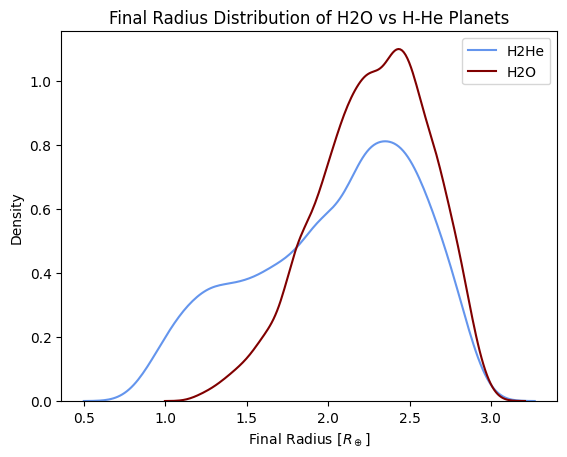

In [41]:
sns.kdeplot(HHe_df['Radius'][1], color='cornflowerblue', label='H2He',legend=True)
sns.kdeplot(H2O_df['Radius'][1], color='maroon', label='H2O', legend=True)
plt.legend()
plt.xlabel('Final Radius [$R_\oplus$]')
plt.title('Final Radius Distribution of H2O vs H-He Planets')

### Steam Valley

Filter planets by period between 0.6-0.9 days, filter entire planet population to this range to constrain at the peak

Constrain to give a quantitative value

Radius gap is period-dependent, so restricting to a slice of data 

In [62]:
steam_valley_bounds=[1.5,1.8]
# print(len())

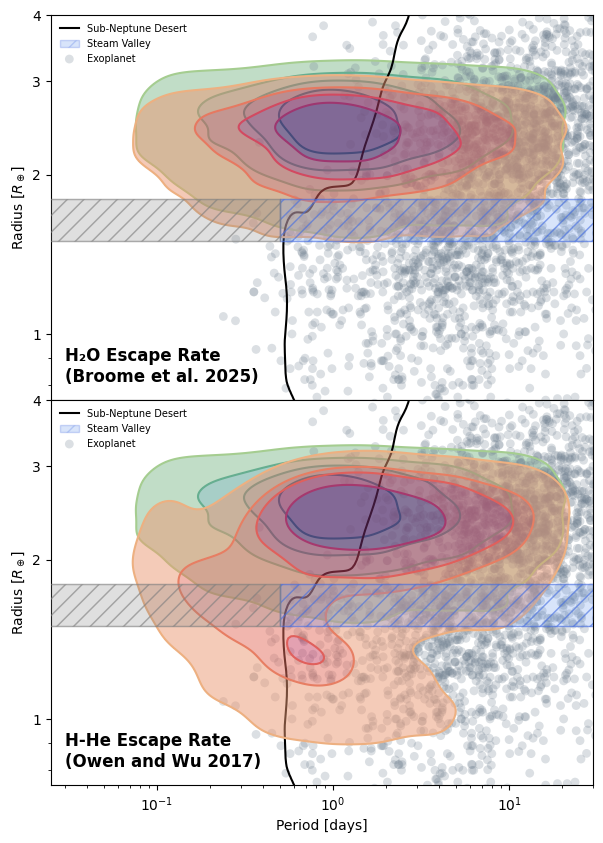

In [67]:
#two panels
types = ['H2O', 'H-He']

fig, ax = plt.subplots(2,1, figsize=(7,10))#, sharex=True)
fig.subplots_adjust(hspace=0)
c1= 'royalblue' #'teal'
c2='cornflowerblue' #'lightseagreen'
for tp in types:
    if tp == 'H2O':
        i=0
        Radius_Final = H2O_df['Radius']
        axis = ax[i]
        axis.set(xscale="log", xlim=(2.5e-2,30), xticks=[],xticklabels=[])
        tl = typelabel[0]

    else:
        i=1
        Radius_Final = HHe_df['Radius']
        axis = ax[i]
        axis.set(xscale="log", xlim=(2.5e-2,30), xlabel="Period [days]")
        tl = typelabel[1]
                # ylabel=r"Radius [$R_\oplus$]", yticks=[1,2,3,4], yticklabels=[1,2,3,4], ylim=(0.75,4))

    for p in range(len(phase)):
        sns.kdeplot(x=iris['period (days)'],y=Radius_Final[p], cmap=colors[p], levels=5, fill=True, alpha=2*fill_a, 
                    log_scale=True, ax=axis, zorder=50*p - 1)
        sns.kdeplot(x=iris['period (days)'],y=Radius_Final[p], cmap=colors[p], levels=5, fill=False, 
                    log_scale=True, ax=axis, zorder=50*p)

    axis.plot(10**des_x, 10**des_y,color='black',lw=1.5, label="Sub-Neptune Desert")
    axis.fill_between(np.linspace(0.5,30,50),steam_valley_bounds[0],steam_valley_bounds[1], color=c1, facecolor='none', alpha=0.5, hatch='//',  zorder=1e3)
    axis.fill_between(np.linspace(0.5,30,50),steam_valley_bounds[0],steam_valley_bounds[1], color=c1, facecolor=c2, alpha=0.25, hatch='//',label="Steam Valley", zorder=1e3)
    # sns.kdeplot(x=iris['period (days)'], y=iris['Rochelim (m)'], levels=3, thresh=0.2, ax=axis, color='rosybrown', label='Roche Limit')
    axis.fill_between(np.linspace(0.01,0.5,50),steam_valley_bounds[0],steam_valley_bounds[1], color="grey", facecolor='none', alpha=0.5, hatch='//',  zorder=1e3)
    axis.fill_between(np.linspace(0.01,0.5,50),steam_valley_bounds[0],steam_valley_bounds[1], color="grey", facecolor="grey", alpha=0.25, hatch='//', zorder=1e3)
    
    # axis.errorbar(list_exo_T,list_exo_rp, xerr=list_exo_Te, yerr=list_exo_rpe, fmt='o',zorder=-10,elinewidth=1, c="slategray",label='Exoplanet',alpha=0.15)  #slategrey
    axis.scatter(P_NEA,R_NEA, ec="none", fc="slategrey", s=40, lw=0.7, alpha=0.25, zorder=-1, label='Exoplanet' )
    axis.text(0.03, 0.8, tl, fontsize='large', weight='semibold', ha='left', va='bottom', zorder=500)
    axis.legend(fontsize=7, facecolor='white', loc='upper left', frameon=False)
    axis.set(ylabel=r"Radius [$R_\oplus$]", yticks=[1,2,3,4], yticklabels=[1,2,3,4], ylim=(0.75,4))

plt.savefig(savepath+f'/sn_desert_{n_planets}xp_stacked.png', pad_inches=0.2, dpi=600)

### sept 10 2026 zoom tests

TO DO
- update steam gap (results)
- 2 runs (M v G) in section 4.4
- section 4.5--shorten down to just be "future work" stuff
- abstract

even though we filtered out roche lobe overflow planets, there are ultra-ultra short period planets (period < 0.5 days) that are very unlikely to exist (Lee Owen 2025).  

In [52]:
# remove planets below 0.5 days

period_mask = iris['period (days)'] > 0.5

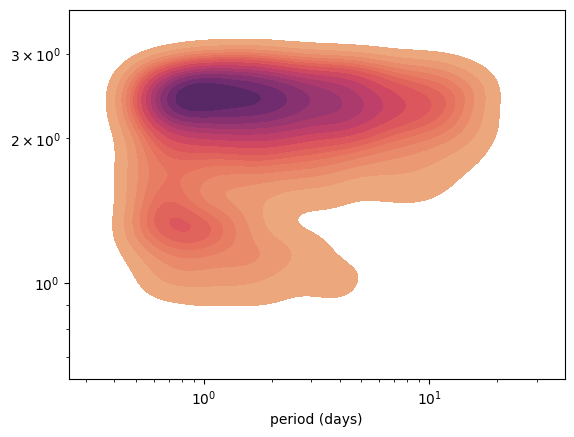

In [ ]:
sns.kdeplot(x=iris['period (days)'][period_mask], y=HHe_df['Radius'][1][period_mask], cmap=colors[1], levels=15, fill=True, 
            log_scale=True)
plt.show()

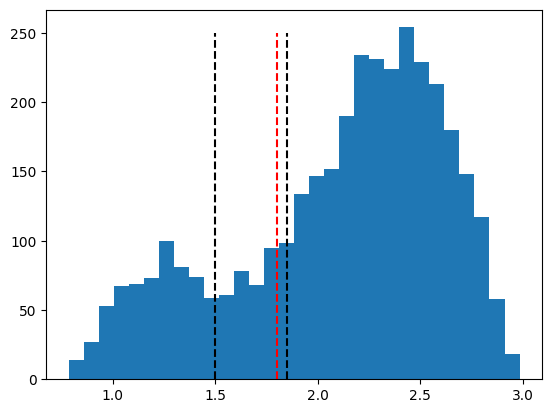

In [61]:
plt.hist(HHe_df['Radius'][1][period_mask], bins=30)
plt.vlines(1.5, 0, 250, color='black', linestyle='--')
plt.vlines(1.8, 0,250, color='red', linestyle='--')
plt.vlines(1.85, 0, 250, color='black', linestyle='--')

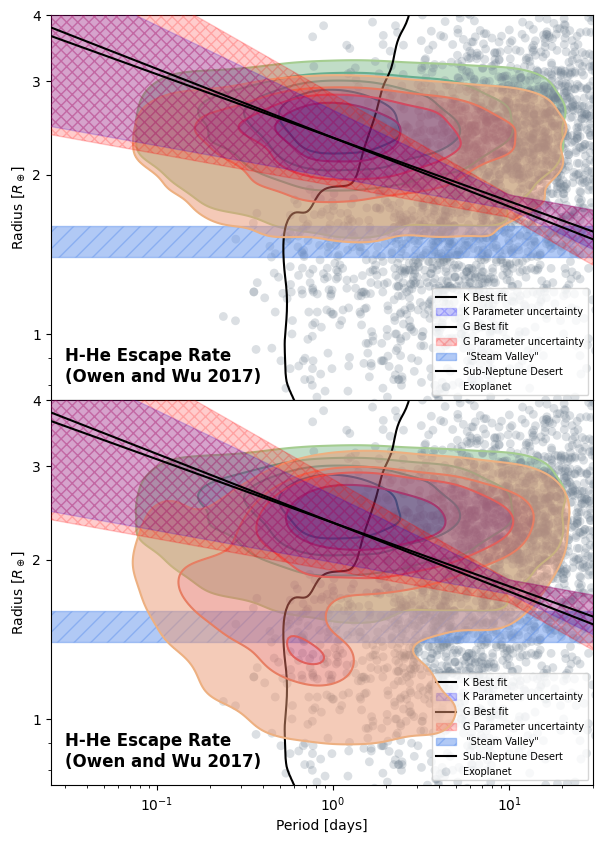

In [227]:
#two panels
fig, ax = plt.subplots(2,1, figsize=(7,10))#, sharex=True)
fig.subplots_adjust(hspace=0) 

for tp in types:
    if tp == 'H2O':
        i=0
        Radius_Final = H2O_df['Radius']
        axis = ax[i]
        axis.set(xscale="log", xlim=(2.5e-2,30), xticks=[],xticklabels=[])

    else:
        i=1
        Radius_Final = HHe_df['Radius']
        axis = ax[i]
        axis.set(xscale="log", xlim=(2.5e-2,30), xlabel="Period [days]")
                # ylabel=r"Radius [$R_\oplus$]", yticks=[1,2,3,4], yticklabels=[1,2,3,4], ylim=(0.75,4))

    for p in range(len(phase)):
        sns.kdeplot(x=iris['period (days)'],y=Radius_Final[p], cmap=colors[p], levels=5, fill=True, alpha=2*fill_a, 
                    log_scale=True, ax=axis, zorder=50*p - 1)
        sns.kdeplot(x=iris['period (days)'],y=Radius_Final[p], cmap=colors[p], levels=5, fill=False, 
                    log_scale=True, ax=axis, zorder=50*p)
    # axis.plot(xx, Rtrans_evap, color='blue', label='Rtrans_evap')
    # axis.plot(xx, Rtrans_rocky, color='red', label='Rtrans_rocky')
    # axis.plot(xx, R_mass_evap, color='green', label='R_mass_evap')

    for i in range(2):
        #for mstar 0.5-0.7
        if i == 0:
            rp_0 = 1.78
            m = -0.12
            rp_0_err= np.array([-0.06, 0.05])
            m_err = np.array([0.06, -0.04])
            label='K'
            color='blue'
        elif i==1:
            rp_0 = 1.74
            m = -0.13
            rp_0_err= np.array([-0.08, 0.09])
            m_err = np.array([0.07, -0.06])
            label='G'
            color='red'

        # Evaluate all combinations of the parameter-error bounds
        rp_bounds = rp_0 + np.asarray(rp_0_err)
        m_bounds = m + np.asarray(m_err)
        radius_bounds = np.array([ r_valley(p_x, rp, slope) for rp in rp_bounds for slope in m_bounds])
        r1 = radius_bounds.min(axis=0)
        r2 = radius_bounds.max(axis=0)
        axis.plot(p_x, r_valley(p_x, rp_0, m), color="black", label=label+" Best fit",zorder=600)
        axis.fill_between(p_x, r1, r2, alpha=0.2, color=color, hatch='xxx', label=label+" Parameter uncertainty", zorder=590)

    axis.fill_between(p_x,1.6,1.4, color='cornflowerblue', alpha=0.5, hatch='//', label=' "Steam Valley"')

    axis.plot(10**des_x, 10**des_y,color='black',lw=1.5, label="Sub-Neptune Desert")
    sns.kdeplot(x=iris['period (days)'], y=iris['Rochelim (m)'], levels=3, thresh=0.2, ax=axis, color='rosybrown', label='Roche Limit')

    axis.scatter(P_NEA,R_NEA, ec="none", fc="slategrey", s=40, lw=0.7, alpha=0.25, zorder=-1, label='Exoplanet' )
    axis.text(0.03, 0.8, typelabel[i], fontsize='large', weight='semibold', ha='left', va='bottom', zorder=500)
    axis.legend(fontsize=7, loc='lower right')#, frameon=False)
    axis.set(ylabel=r"Radius [$R_\oplus$]", yticks=[1,2,3,4], yticklabels=[1,2,3,4], ylim=(0.75,4))

plt.savefig(savepath+f'/sn_desert_{n_planets}xp_stacked_regions.png', pad_inches=0.2, dpi=600)

In [171]:
# lopez rice 2016
Rtrans = iris['sep (m)']**0.16 * iris['Mstar (kg)']**(-0.14)
RHill =  iris['sep (m)'] * (iris['Mp (kg)'] / (3*iris['Mstar (kg)']))**(1/3)

xx = np.logspace(-2, 2, 50)

Rtrans_rocky = xx ** (0.11)
Rtrans_evap = xx ** (-0.15)

R_mass_evap = xx ** (-0.25) #radius of the most massive planets that can be stripped of h-he

Rtrans_rocky = xx ** (-0.11)
    # axis.hlines(1.3, 0.1, 20, color='brown', label='SE peak')